# FASE 1. COMPRENSIÓN DE LOS DATOS - ESTACIONES (EEA)

## 1. Carga y observaciones iniciales

In [1]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("TFM_Estaciones_Valencia") \
    .getOrCreate()

print("Spark funcionando correctamente")
print("Versión de Spark:", spark.version)

Spark funcionando correctamente
Versión de Spark: 3.3.2


26/10/24 17:04:27 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.


In [2]:
# Nombre de nuestro bucket
bucket = "gs://tfm_unir1"

# Ruta donde están los datos
ruta_estaciones = f"{bucket}/estaciones/"

# Acceder al sistema de archivos de Google Cloud Storage
path = spark._jvm.org.apache.hadoop.fs.Path(ruta_estaciones)

fs = path.getFileSystem(spark._jsc.hadoopConfiguration())

# Listar archivos entrando a subcarpetas
iterador = fs.listFiles(path, True)

archivos = []

while iterador.hasNext():
    archivos.append(iterador.next().getPath().toString())
    
print("Número de elementos encontrados:", len(archivos))

for archivo in archivos[:10]:
    print(archivo)

Número de elementos encontrados: 2
gs://tfm_unir1/estaciones/eea_metadatos.tsv
gs://tfm_unir1/estaciones/estaciones_estacions-contaminacio-atmosferiques-estaciones-contaminacion-atmosfericas.csv


Se utilizará solo eea_metadatos porque tiene las estaciones de Valencia con sus códigos, nombre, tipo, zona, coordenadas y se puede unir con los datasets de aire

## 2. Análisis de archivo

In [7]:
from pyspark.sql import functions as F

ruta_estaciones = "gs://tfm_unir1/estaciones/eea_metadatos.tsv"

# Cargar el archivo
df = (spark.read
                .option("header", True)
                .option("sep", ",")
                .option("quote", '"')
                .option("escape", '"')
                .option("multiline", True)
                .csv(ruta_estaciones))



# Mostrar la estructura de las columnas
df.printSchema()

# Mostrar las primeras 5 filas
df.show(5, truncate=False)



root
 |-- Country: string (nullable = true)
 |-- B-G Namespace: string (nullable = true)
 |-- Year: string (nullable = true)
 |-- Air Quality Network: string (nullable = true)
 |-- Air Quality Network Name: string (nullable = true)
 |-- Timezone: string (nullable = true)
 |-- Air Quality Station EoI Code: string (nullable = true)
 |-- Air Quality Station Nat Code: string (nullable = true)
 |-- Air Quality Station Name: string (nullable = true)
 |-- Sampling Point Id: string (nullable = true)
 |-- Air Pollutant: string (nullable = true)
 |-- Longitude: string (nullable = true)
 |-- Latitude: string (nullable = true)
 |-- Altitude: string (nullable = true)
 |-- Altitude Unit: string (nullable = true)
 |-- Air Quality Station Area: string (nullable = true)
 |-- Air Quality Station Type: string (nullable = true)
 |-- Operational Activity Begin: string (nullable = true)
 |-- Operational Activity End: string (nullable = true)
 |-- Sample Id: string (nullable = true)
 |-- Inlet Height: string

DataFrame[summary: string, Country: string, B-G Namespace: string, Year: string, Air Quality Network: string, Air Quality Network Name: string, Timezone: string, Air Quality Station EoI Code: string, Air Quality Station Nat Code: string, Air Quality Station Name: string, Sampling Point Id: string, Air Pollutant: string, Longitude: string, Latitude: string, Altitude: string, Altitude Unit: string, Air Quality Station Area: string, Air Quality Station Type: string, Operational Activity Begin: string, Operational Activity End: string, Sample Id: string, Inlet Height: string, Inlet Height Unit: string, Building Distance: string, Building Distance Unit: string, Kerb Distance: string, Kerb Distance Unit: string, Distance Source: string, Distance Source Unit: string, Main Emission Sources: string, Heating Emissions: string, Heating Emissions Unit: string, Mobile: string, Traffic Emissions: string, Traffic Emissions Unit: string, Industrial Emissions: string, Industrial Emissions Unit: string,

**Observaciones:**
El fichero de metadatos de la EEA contiene 70 columnas y cubre todas las estaciones de Europa.
Para el TFM solo necesitamos identificar cada estación de Valencia y describirla, por lo que trabajaremos con 11 campos:

- **Identificación**: código nacional (`station_code`, clave de unión con los datos de aire GVA y EEA), código europeo y nombre.
- **Clasificación**: tipo de estación (tráfico, fondo, industrial) y zona (urbana, suburbana, rural). Permite comparar estaciones expuestas al tráfico con estaciones de fondo.
- **Ubicación**: latitud, longitud y altitud.
- **Periodo de funcionamiento**: fecha de alta, fecha de baja y año de los metadatos. Permite saber qué estaciones siguen activas en el periodo de estudio.

Se descartan:
- **Detalle técnico del sensor** (método, equipo, límite de detección, frecuencia): no aporta al análisis.
- **Entorno de la estación** (emisiones de tráfico, calefacción e industria, volumen de tráfico, anchura de calle): el tráfico ya se obtiene con mayor detalle de las espiras.

Se filtran las estaciones de València por el código nacional (prefijo '46250').

In [9]:
# Armamos df_estaciones usando las columnas que necesitamos
df_estaciones = (df
                .filter(F.col("Air Quality Station Nat Code").startswith("46250"))
                .select(
                    F.col("Air Quality Station Nat Code").alias("id_estacion"),
                    F.col("Air Quality Station EoI Code").alias("codigo_eea"),
                    F.col("Air Quality Station Name").alias("nombre_estacion"),
                    F.col("Air Quality Station Type").alias("tipo_estacion"),
                    F.col("Air Quality Station Area").alias("zona"),
                    F.col("Latitude").alias("latitud"),
                    F.col("Longitude").alias("longitud"),
                    F.col("Altitude").alias("altitud"),
                    F.col("Operational Activity Begin").alias("fecha_alta"),
                    F.col("Operational Activity End").alias("fecha_baja"),
                    F.col("Year").alias("anio"),
                    F.col("Air Pollutant").alias("contaminante")

                ))

print("Registros:", df_estaciones.count())
df_estaciones.show(10, truncate=False)

Registros: 390


+-----------+----------+-----------------------+-------------+-----+---------+---------+---------+-------------------+----------+----+------------+
|id_estacion|codigo_eea|nombre_estacion        |tipo_estacion|zona |latitud  |longitud |altitud  |fecha_alta         |fecha_baja|anio|contaminante|
+-----------+----------+-----------------------+-------------+-----+---------+---------+---------+-------------------+----------+----+------------+
|46250030   |ES1239A   |VALÈNCIA-PISTA DE SILLA|traffic      |urban|39.456110|-0.375830|11.000000|01/07/1992 00:00:00|null      |2025|SO2         |
|46250030   |ES1239A   |VALÈNCIA-PISTA DE SILLA|traffic      |urban|39.456110|-0.375830|11.000000|01/01/2009 00:00:00|null      |2025|PM10        |
|46250030   |ES1239A   |VALÈNCIA-PISTA DE SILLA|traffic      |urban|39.456110|-0.375830|11.000000|01/01/2018 00:00:00|null      |2025|PM10        |
|46250030   |ES1239A   |VALÈNCIA-PISTA DE SILLA|traffic      |urban|39.456110|-0.375830|11.000000|01/07/1992 00:

- Cada estación aparece en varias filas: una por contaminante medido.

In [14]:
# Ver volumen y numero de estaciones
df_estaciones.agg(
    F.count("*").alias("total_registros"),
    F.countDistinct("id_estacion").alias("total_estaciones"),
    F.countDistinct("codigo_eea").alias("total_codigo_eea"),
    F.countDistinct("nombre_estacion").alias("total_nombre_estacion")
    ).show(20)

+---------------+----------------+----------------+---------------------+
|total_registros|total_estaciones|total_codigo_eea|total_nombre_estacion|
+---------------+----------------+----------------+---------------------+
|            390|              14|              14|                   20|
+---------------+----------------+----------------+---------------------+



### Evaluación inicial de la calidad de los datos

In [17]:
from pyspark.sql import functions as F

# Comprobar los nulos por columnas
df_estaciones.select(
    F.sum(F.col("id_estacion").isNull().cast("int")).alias("codigo_estacion_nulos"),
    F.sum(F.col("codigo_eea").isNull().cast("int")).alias("codigo_eea_nulos"),
    F.sum(F.col("nombre_estacion").isNull().cast("int")).alias("nombre_estacion_nulos"),
    F.sum(F.col("tipo_estacion").isNull().cast("int")).alias("tipo_estacion_nulos"),
    F.sum(F.col("zona").isNull().cast("int")).alias("zona_nulos"),
    F.sum(F.col("latitud").isNull().cast("int")).alias("latitud_nulos"),
    F.sum(F.col("longitud").isNull().cast("int")).alias("longitud_nulos"),
    F.sum(F.col("altitud").isNull().cast("int")).alias("altitud_nulos"),
    F.sum(F.col("fecha_alta").isNull().cast("int")).alias("fecha_alta_nulos"),
    F.sum(F.col("fecha_baja").isNull().cast("int")).alias("fecha_baja_nulos"),
    F.sum(F.col("anio").isNull().cast("int")).alias("anio_nulos"),
    F.sum(F.col("contaminante").isNull().cast("int")).alias("contaminante_nulos"),
    
).show()

+---------------------+----------------+---------------------+-------------------+----------+-------------+--------------+-------------+---------------+----------------+----------+------------------+
|codigo_estacion_nulos|codigo_eea_nulos|nombre_estacion_nulos|tipo_estacion_nulos|zona_nulos|latitud_nulos|longitud_nulos|altitud_nulos|fecha_altanulos|fecha_baja_nulos|anio_nulos|contaminante_nulos|
+---------------------+----------------+---------------------+-------------------+----------+-------------+--------------+-------------+---------------+----------------+----------+------------------+
|                    0|               0|                    0|                  0|         0|            0|             0|            0|              0|             302|       283|                 0|
+---------------------+----------------+---------------------+-------------------+----------+-------------+--------------+-------------+---------------+----------------+----------+------------------+


- No hay nulos en la mayoria de los campos.
- Tenemos nulos en fecha_baja lo cual no es un error si la estacion aun esta activa.
- El campo anio tiene 283 nulos (73%). Analizaremos este campo en detaclle

In [18]:
# Revisar los nulos de fecha_baja y anio por estacion
tabla = (df_estaciones.groupBy("id_estacion", "nombre_estacion")
           .pivot("anio")
           .agg(F.count("*")))

tabla.show()

+-----------+--------------------+----+----+
|id_estacion|     nombre_estacion|null|2025|
+-----------+--------------------+----+----+
|   46250030|"ES1239A-VALÈNCIA...|  27|null|
|   46250034|   "ES1172A-LINARES"|  14|null|
|   46250055|  VALÈNCIA OLIVERETA|null|   5|
|   46250031|"ES1240A-NUEVO CE...|  18|null|
|   46250033|    "ES1171A-ARAGÓN"|  22|null|
|   46250038|   "ES1584A-NAZARET"|  24|null|
|   46250050|"ES1970A-VALÈNCIA...|  46|null|
|   46250043|"ES1619A-VALÈNCIA...|  64|null|
|   46250046|"ES1885A-VALÈNCIA...|  16|null|
|   46250047|"ES1912A-VALÈNCIA...|  18|null|
|   46250047|VALÈNCIA - AVD. F...|null|   8|
|   46250030|VALÈNCIA-PISTA DE...|null|  16|
|   46250043|     VALÈNCIA-VIVERS|null|  21|
|   46250051|   VALENCIA-ALBUFERA|null|   9|
|   46250046| VALÈNCIA-POLITÈCNIC|null|  11|
|   46250054|     VALÈNCIA-CENTRE|null|   5|
|   46250048|VALÈNCIA - MOLÍ D...|null|  12|
|   46250050|VALÈNCIA - BULEVA...|null|  20|
|   46250048|"ES1926A-VALÈNCIA...|  18|null|
|   462500

Analizando estos datos, observamos:
- Existen registros distintos para la misma estacion (ej.: “ES1239A-VALÈNCIA-PISTA DE SILLA” y "VALÈNCIA-PISTA DE SILLA"). La misma estacion con dos formas distintas de nombre
- El fichero mezcla registros antiguos (con el campo anio en null) y registros nuevos de la misma estacion con el campo anio completo

Concluimos que el campo anio NULL no es un error y se corregirá durante la limpieza

In [20]:
tabla = (df_estaciones.groupBy("id_estacion", "nombre_estacion")
           .pivot("fecha_baja")
           .agg(F.count("*")))

tabla.show()

+-----------+--------------------+----+-------------------+-------------------+-------------------+-------------------+-------------------+-------------------+-------------------+-------------------+-------------------+-------------------+-------------------+
|id_estacion|     nombre_estacion|null|01/01/2007 00:00:00|01/03/2006 00:00:00|04/04/2008 00:00:00|07/08/2009 00:00:00|15/02/2002 00:00:00|20/11/2001 00:00:00|26/03/2014 00:00:00|27/03/2014 00:00:00|31/10/2014 00:00:00|31/12/2009 00:00:00|31/12/2013 00:00:00|
+-----------+--------------------+----+-------------------+-------------------+-------------------+-------------------+-------------------+-------------------+-------------------+-------------------+-------------------+-------------------+-------------------+
|   46250030|"ES1239A-VALÈNCIA...|  27|               null|               null|               null|               null|               null|               null|               null|               null|               null| 

Analizando estos datos, observamos:

- Hay estaciones activas e inactivas. Las inactivas tienen fecha_baja no null. Las activas tienen valor en este campo.

Concluimos que el campo anio NULL no es un error

In [21]:
# Comprobamos si existen registros duplicados
print("Número de combinaciones duplicadas:", df_estaciones.count() - df_estaciones.dropDuplicates().count())


Número de combinaciones duplicadas: 163


In [22]:
# Analizamos los duplicados para decidir como proseguir
(df_estaciones.groupBy("id_estacion").count()
   .filter(F.col("count") > 1)
   .count())

14

In [24]:
# Analizamos una estacion para entender los 163 duplicados
df_estaciones.filter(F.col("id_estacion") == "46250030") \
    .orderBy("contaminante", "anio") \
    .toPandas()

,id_estacion,codigo_eea,nombre_estacion,tipo_estacion,zona,latitud,longitud,altitud,fecha_alta,fecha_baja,anio,contaminante
0,46250030,ES1239A,"""ES1239A-VALÈNCIA-PISTA DE SILLA""",traffic,urban,39.456110,-0.375830,11.000000,01/01/2014 00:00:00,None,None,C6H4-(CH3)2
1,46250030,ES1239A,VALÈNCIA-PISTA DE SILLA,traffic,urban,39.456110,-0.375830,11.000000,01/01/2014 00:00:00,None,2025,C6H4-(CH3)2
2,46250030,ES1239A,"""ES1239A-VALÈNCIA-PISTA DE SILLA""",traffic,urban,39.456110,-0.375830,11.000000,01/01/2014 00:00:00,None,None,C6H5-CH3
3,46250030,ES1239A,VALÈNCIA-PISTA DE SILLA,traffic,urban,39.456110,-0.375830,11.000000,01/01/2014 00:00:00,None,2025,C6H5-CH3
4,46250030,ES1239A,"""ES1239A-VALÈNCIA-PISTA DE SILLA""",traffic,urban,39.456110,-0.375830,11.000000,27/03/2014 00:00:00,None,None,C6H6
5,46250030,ES1239A,VALÈNCIA-PISTA DE SILLA,traffic,urban,39.456110,-0.375830,11.000000,27/03/2014 00:00:00,None,2025,C6H6
6,46250030,ES1239A,"""ES1239A-VALÈNCIA-PISTA DE SILLA""",traffic,urban,39.456110,-0.375830,11.000000,01/07/1992 00:00:00,None,None,CO
7,46250030,ES1239A,"""ES1239A-VALÈNCIA-PISTA DE SILLA""",traffic,urban,39.456110,-0.375830,11.000000,01/07/1992 00:00:00,None,None,CO
8,46250030,ES1239A,VALÈNCIA-PISTA DE SILLA,traffic,urban,39.456110,-0.375830,11.000000,01/07/1992 00:00:00,None,2025,CO
9,46250030,ES1239A,"""ES1239A-VALÈNCIA-PISTA DE SILLA""",traffic,urban,39.456110,-0.375830,11.000000,01/07/1992 00:00:00,None,None,NO


- Una misma estacion aparece varias veces porque cambia el contaminante y su nombre como analizamos anteriormente

**Limpieza:** Agrupar las estaciones por id_estacion y solo conservar el registro cuyo anio no sea NULL usando como fecha_alta la minima. El campo contaminante puede ser descartado. 
Hay estaciones que desaparecerán porque tienen campo anio null pero son antiguas y no estan presentes en nuestros analisis desde 2023 a 2025

In [27]:
# Analisis de valores extremos (latitud, longitud)
df_estaciones.select ("id_estacion", "latitud", "longitud", "altitud")\
    .distinct()\
    .orderBy("id_estacion")\
    .toPandas()


,id_estacion,latitud,longitud,altitud
0,46250030,39.456110,-0.375830,11.000000
1,46250031,39.481390,-0.388060,11.000000
2,46250032,39.468330,-0.380830,11.000000
3,46250033,39.475560,-0.352220,11.000000
4,46250034,39.463330,-0.391940,11.000000
5,46250038,39.448890,-0.673610,15.000000
6,46250043,39.478060,-0.368330,11.000000
7,46250046,39.480300,-0.336400,7.000000
8,46250046,39.480280,-0.336390,7.000000
9,46250047,39.457500,-0.342780,7.000000


Solo la estacion 46250038 posee una longitud invalida. Como será descartada porque es una estacion antigua, no será necesario hacer otra limpieza.

### Análisis exploratorio preliminar

In [29]:
# Numero de estaciones por tipo y zona
from pyspark.sql import functions as F

df_estaciones.groupBy ("tipo_estacion", "zona")\
    .agg(F.countDistinct("id_estacion").alias("estaciones"))\
    .orderBy("tipo_estacion", "zona")\
    .toPandas()


,tipo_estacion,zona,estaciones
0,background,rural,1
1,background,suburban,1
2,background,urban,3
3,traffic,suburban,1
4,traffic,urban,10


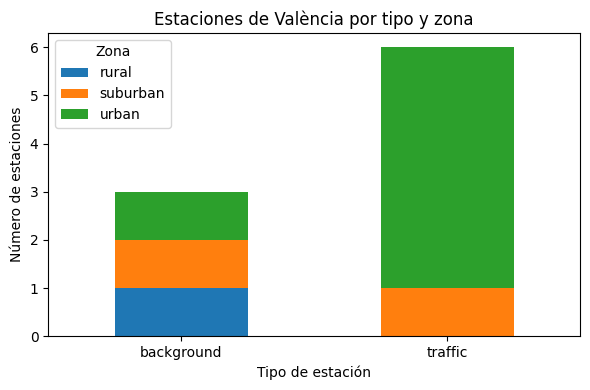

In [30]:
import matplotlib.pyplot as plt

# Estaciones por tipo y zona (solo registros de 2025)
pdf = (df_estaciones
    .filter(F.col("anio").isNotNull())
    .groupBy("tipo_estacion", "zona")
    .agg(F.countDistinct("id_estacion").alias("estaciones"))
    .toPandas())

# Gráfico de barras apiladas: una barra por tipo, colores por zona
tabla = pdf.pivot(index="tipo_estacion", columns="zona", values="estaciones").fillna(0)

tabla.plot(kind="bar", stacked=True, figsize=(6, 4))
plt.title("Estaciones de València por tipo y zona")
plt.xlabel("Tipo de estación")
plt.ylabel("Número de estaciones")
plt.xticks(rotation=0)
plt.legend(title="Zona")
plt.tight_layout()
plt.show()

- De las 9 estaciones de los registros de 2025, 6 son de trafico y 3 de fondo
- Si se incorpora la comprarción entre trafico y fondo, hay pocas estaciones de fondo y eso puede representar una limitacion para el analisis 

### Identificación de valores extremos

Esta sección ya fue analizada anteriormente cuando detectamos valores inválidos

### Registros duplicados

Ya fueron analizados anteriormente